**Rules for the code:**

- Include all the code you used for your report in this file. The code for any section in the report should go under the same section in this file.
- Any missing code will result in -20% from its corresponding section in the report.
- Any irrelevant code will result in -20% from its corresponding section in the report.
- Make sure that you run your code before rendering so that all the necessary visual/numeric outputs are visible.
- Any code that is not properly run or throws errors will be considered missing/irrelevant.

In [153]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
import statsmodels.formula.api as smf
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
import warnings
warnings.filterwarnings('ignore')

## 4) Data

- Identify and describe your data source(s). Include the links/citations, so the readers can access the data.
- Describe **(no code or code output here)** the following:
    - How many observations and variables does the dataset have?
    - What does each observation and variable represent?
    - How many variables are numeric and how many variables are categorical?
    - Which variables are the predictors and which variable is the response?
 
If the data needed to be cleaned for your analysis, **briefly** describe the steps you took to clean the data. (Data cleaning was last quarter's focus, so it should not be a major part of this report.) **If the data was clean, state "cleaning was not necessary."**
 
**(2 points)**

In [154]:
# Read data
data = pd.read_csv('traffic_data.csv')

In [155]:
data.head()

,DR Number,Date Reported,Date Occurred,Time Occurred,Area ID,Area Name,Reporting District,Crime Code,Crime Code Description,MO Codes,Victim Age,Victim Sex,Victim Descent,Premise Code,Premise Description,Address,Cross Street,Location
0,212013850,09/03/2021,09/02/2021,2335,20,Olympic,2021,997,TRAFFIC COLLISION,3004 3027 3034 4027 3036 3101 3401 3701,25.0,F,W,101.0,STREET,WILTON PL,6TH ST,"(34.063, -118.3141)"
1,221417787,10/17/2022,10/17/2022,1620,14,Pacific,1406,997,TRAFFIC COLLISION,4027 3011 3028 3034 3037 3101 3401 3701,21.0,NaN,NaN,101.0,STREET,NATIONAL BL,MOTOR AV,"(34.029, -118.4113)"
2,221418141,10/26/2022,10/26/2022,1135,14,Pacific,1434,997,TRAFFIC COLLISION,4027 3011 3025 3034 3037 3101 3401 3701,21.0,NaN,NaN,101.0,STREET,PALMS BL,ROSEWOOD AV,"(34.0052, -118.4478)"
3,222017859,12/01/2022,12/01/2022,230,20,Olympic,2044,997,TRAFFIC COLLISION,3003 0913 3026 3035 3037 3101 3401 3701 4020,33.0,M,H,101.0,STREET,IROLO ST,SAN MARINO ST,"(34.0545, -118.3009)"
4,190319651,08/24/2019,08/24/2019,450,3,Southwest,356,997,TRAFFIC COLLISION,3036 3004 3026 3101 4003,22.0,M,H,101.0,STREET,JEFFERSON BL,NORMANDIE AV,"(34.0255, -118.3002)"


In [156]:
## HERE WE WILL REUSE FUNCTIONS USED TO CLEAN REDUNDANT VARIABLES AND FIX MO CODES COLUMN 
# WE USE MO CODES THAT WE SUSPECT MAY GIVE US VALUABLE INFORMATION + THIS IS ALSO WHERE WE CATEGORIZE ACCIDENTS BY FATAL/NON-FATAL (SINCE FATAL IS AN MO CODE) 
dataNoRedundancy=data.drop(columns=['DR Number','Date Reported', 'Area ID', 'Crime Code','Crime Code Description', 'Premise Code', 'Address', 'Cross Street', 'Location', 'Reporting District','Victim Descent'])
cleanCodes = dataNoRedundancy.copy()[dataNoRedundancy['MO Codes'].isna() == False]
def fatalTF(x):
    if ('3027' in x):
        return True
    else: 
        return False
def vehVs(x):
    #This function identifies with what the vehicle has collided, if there is not a vehicle involved we return None and filter these points out
    # FOR THE SAKE OF THIS PROJECT WE CONSIDER 'VEHICLE VS BIKE' AS THE SAME AS 'BIKE VS VEHICLE' IN PRACTICE THESE MAY HAVE DIFFERENT COEFFICIENTS
    if ('3003' in x):
        return 'Pedestrian'
    elif ('3011' in x) or ('3012' in x):
        return 'Object'
    elif ('3008' in x) or ('3016' in x):
        return 'Bike'
    elif ('3004' in x):
        return 'Vehicle'
    elif ('3007' in x) or ('3019' in x):
        return 'Train'
    elif ('3006' in x):
        return 'Parked Vehicle'
    elif ('3005' in x):
        return 'Vehicle On Other Roadway'
    else: 
        return np.nan
cleanCodes['Fatal'] = cleanCodes['MO Codes'].apply(fatalTF)
cleanCodes['Hit'] = cleanCodes['MO Codes'].apply(vehVs)
cleanCodes = cleanCodes.drop(columns = 'MO Codes')

In [157]:
# Putting time into continuous integer format
def timeToMins(x):
    asString = str(x)
    while len(asString) < 4:
        asString = '0' + asString
    return 60 * int(asString[:2]) + int(asString[2:])
cleanCodes['Minutes'] = cleanCodes['Time Occurred'].apply(timeToMins)
cleanCodes = cleanCodes.drop(columns = 'Time Occurred')

In [158]:
cleanCodes['Month'] = cleanCodes['Date Occurred'].apply(lambda x:  int(x[:2]))
cleanCodes['Day'] = cleanCodes['Date Occurred'].apply(lambda x:  int(x[3:5]))
cleanCodes['Year'] = cleanCodes['Date Occurred'].apply(lambda x:  int(x[6:]))
cleanCodes = cleanCodes.drop(columns='Date Occurred')

In [159]:
cleanCodes['Hit'].value_counts()
# Here is the breakdown of how many times each of the following were in an accident with a car (Vehicle means both were cars)

Hit
Vehicle                     268261
Parked Vehicle              117733
Object                       40657
Pedestrian                   36900
Bike                         21140
Vehicle On Other Roadway       546
Train                          221
Name: count, dtype: int64

In [160]:
cleanData = cleanCodes.dropna()
# Here we remove all null predictors, since they aren't helpful for training

In [161]:
# Next we will remove categories from categorical variables for which we have very little data (ex: Cemetary appears as a premise only once, it'd be unreasonale to give it a coefficient)
cleanData = cleanData[cleanData['Victim Sex'].isin(['M','F'])]
#We will only be considering male and female victims. There is not a consistently defined way within LAPD codes to define non-binary/gender fluid victims. Other values indicate Unknown gender
premiseCounts = cleanData['Premise Description'].value_counts()
validPremises = list(premiseCounts[cleanData['Premise Description'].value_counts() > 100].index)
cleanData = cleanData[cleanData['Premise Description'].apply(lambda x: True if x in validPremises else False)]
# We keep 9 premises. Our choice of 100 is somewhat arbitraty, solely based on not wanting too many predictors after one-hot encoding
cleanData.shape
#We still have > 400000 observations

(408460, 10)

In [162]:
#We also will rename columns to replace spaces with underscores for legibility
newColNames = []
for i in cleanData.columns:
    newColNames.append(i.replace(' ','_'))
cleanData.columns = newColNames

## 5) Prediction

In [163]:
X = cleanData[['Area_Name', 'Victim_Age', 'Victim_Sex',
       'Premise_Description', 'Hit', 'Minutes',
       'Month', 'Day', 'Year']]
y = cleanData['Fatal']
# Here we slice all predictors we are considering, although we wont start with all of them

In [164]:
X.head()
#Here we see our predictors. They still need to be one-hot encoded, but we will do that as we introduce new predictors to the model

,Area_Name,Victim_Age,Victim_Sex,Premise_Description,Hit,Minutes,Month,Day,Year
0,Olympic,25.0,F,STREET,Vehicle,1415,9,2,2021
3,Olympic,33.0,M,STREET,Pedestrian,150,12,1,2022
4,Southwest,22.0,M,STREET,Vehicle,290,8,24,2019
5,Southwest,30.0,F,STREET,Parked Vehicle,1400,8,30,2019
7,Central,21.0,M,STREET,Object,230,11,20,2019


In [165]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [166]:
X_train_ohe = pd.get_dummies(X_train)
X_test_ohe = pd.get_dummies(X_test)
scaler= StandardScaler()
scaler.fit(X_train_ohe)
X_train_scaled = scaler.transform(X_train_ohe)
X_test_scaled = scaler.transform(X_test_ohe)

In [167]:
poly = PolynomialFeatures(degree = 2,interaction_only=False,include_bias=False)
X_train_poly = poly.fit_transform(X_train_ohe)
X_test_poly = poly.fit_transform(X_test_ohe)
scaler = StandardScaler()
scaler.fit(X_train_poly)
X_train_poly_scaled = scaler.transform(X_train_poly)
X_test_poly_scaled = scaler.transform(X_test_poly)

In [168]:
#First model. We will use victim_age first since it is linear and expected to be correlated with fatality (older people would be more vulnurable)
basemodel = LogisticRegression(penalty=None)
basemodel.fit(X_train[['Victim_Age']], y_train)
y_pred = basemodel.predict_proba(X_test[['Victim_Age']])[:,1] > 0.01
y_train_pred = basemodel.predict_proba(X_train[['Victim_Age']])[:,1] > 0.01
# we will tune the exact threshold later, but it is immediately clear to me that, especially since we care most about recall, we will use an exceptionally low threshold
# Our model does not output any values above the default threshold of 0.5 nor does it get particularly close. We will use 0.01 for now 
scores = {}
train_acc, train_rec, train_roc_auc = accuracy_score(y_train,y_train_pred), recall_score(y_train,y_train_pred), roc_auc_score(y_train,basemodel.predict_proba(X_train[['Victim_Age']])[:,1])
test_acc, test_rec, test_roc_auc = accuracy_score(y_test,y_pred), recall_score(y_test,y_pred), roc_auc_score(y_test,basemodel.predict_proba(X_test[['Victim_Age']])[:,1])
scores['base model (age)'] = {'train acc':train_acc, 'train rec':train_rec, 'train roc auc':train_roc_auc, 'test acc':test_acc,'test rec':test_rec,'test roc auc':test_roc_auc}
print('base model training accuracy:',accuracy_score(y_train,y_train_pred))
print('base model training recall:',recall_score(y_train,y_train_pred))
print('base model training roc_auc',roc_auc_score(y_train,basemodel.predict_proba(X_train[['Victim_Age']])[:,1]))
print('base model test accuracy:',accuracy_score(y_test,y_pred))
print('base model test recall:',recall_score(y_test,y_pred))
print('base model test roc_auc',roc_auc_score(y_test,basemodel.predict_proba(X_test[['Victim_Age']])[:,1]))

base model training accuracy: 0.9162769916270871
base model training recall: 0.19061302681992337
base model training roc_auc 0.6149754774757297
base model test accuracy: 0.9166381040983205
base model test recall: 0.2361111111111111
base model test roc_auc 0.6270445516031379


In [169]:
for i in range(2,10):
    X_train_slice = pd.get_dummies(X_train[X_train.columns[:i]])
    X_test_slice = pd.get_dummies(X_test[X_train.columns[:i]])
    model = LogisticRegression(penalty=None)
    model.fit(X_train_slice, y_train)
    y_test_probs = model.predict_proba(X_test_slice)[:,1]
    y_train_probs = model.predict_proba(X_train_slice)[:,1]
    y_test_pred = y_test_probs > 0.01
    y_train_pred = y_train_probs > 0.01
    train_acc, train_rec, train_roc_auc = accuracy_score(y_train,y_train_pred), recall_score(y_train,y_train_pred), roc_auc_score(y_train,y_train_probs)
    test_acc, test_rec, test_roc_auc = accuracy_score(y_test,y_test_pred), recall_score(y_test,y_test_pred), roc_auc_score(y_test,y_test_probs)
    scores[X.columns[i-1]] = {'train acc':train_acc, 'train rec':train_rec, 'train roc auc':train_roc_auc, 'test acc':test_acc,'test rec':test_rec,'test roc auc':test_roc_auc}


In [170]:
Cs = np.logspace(2,-2,200)
poly_model = LogisticRegressionCV(penalty='l2', Cs = Cs, cv = 5)
# Since our dataset is so large, we are not particularly worried about having a high number of folds
poly_model.fit(X_train_poly_scaled,y_train)

,"Cs Cs: int or list of floats, default=10Each of the values in Cs describes the inverse of regularizationstrength. If Cs is as an int, then a grid of Cs values are chosenin a logarithmic scale between 1e-4 and 1e4.Like in support vector machines, smaller values specify strongerregularization.",array([1.0000...00000000e-02])
,"l1_ratios l1_ratios: array-like of shape (n_l1_ratios), default=NoneFloats between 0 and 1 passed as Elastic-Net mixing parameter (scaling betweenL1 and L2 penalties). For `l1_ratio = 0` the penalty is an L2 penalty. For`l1_ratio = 1` it is an L1 penalty. For `0 < l1_ratio < 1`, the penalty is acombination of L1 and L2.All the values of the given array-like are tested by cross-validation and theone giving the best prediction score is used... warning:: Certain values of `l1_ratios`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `l1_ratios=None` is deprecated in 1.8 and will raise an error in version 1.10. Default value will change from `None` to `(0.0,)` in version 1.10.",'warn'
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"cv cv: int or cross-validation generator, default=NoneThe default cross-validation generator used is Stratified K-Folds.If an integer is provided, it specifies the number of folds, `n_folds`, used.See the module :mod:`sklearn.model_selection` module for thelist of possible cross-validation objects... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer dual=False whenn_samples > n_features.",False
,"penalty penalty: {'l1', 'l2', 'elasticnet'}, default='l2'Specify the norm of the penalty:- `'l2'`: add a L2 penalty term (used by default);- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'l2'
,"scoring scoring: str or callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: :ref:`accuracy ` is used.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' might be slower in :class:`LogisticRegressionCV` because it does not handle warm-starting.- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme fo

In [171]:
y_test_probs = poly_model.predict_proba(X_test_poly_scaled)[:,1]
y_train_probs = poly_model.predict_proba(X_train_poly_scaled)[:,1]
y_test_pred = y_test_probs > 0.01
y_train_pred = y_train_probs > 0.01
train_acc, train_rec, train_roc_auc = accuracy_score(y_train,y_train_pred), recall_score(y_train,y_train_pred), roc_auc_score(y_train,y_train_probs)
test_acc, test_rec, test_roc_auc = accuracy_score(y_test,y_test_pred), recall_score(y_test,y_test_pred), roc_auc_score(y_test,y_test_probs)
scores['Polynomial'] = {'train acc':train_acc, 'train rec':train_rec, 'train roc auc':train_roc_auc, 'test acc':test_acc,'test rec':test_rec,'test roc auc':test_roc_auc}

In [172]:
best_c = poly_model.C_[0]
print('selected c:',best_c)

selected c: 0.010473708979594498


In [173]:
scores['Polynomial']

{'train acc': 0.8901177593889242,
 'train rec': 0.735632183908046,
 'train roc auc': 0.8954687826729012,
 'test acc': 0.8924741712774813,
 'test rec': 0.7242063492063492,
 'test roc auc': 0.8864683849595412}

In [174]:
# Our accuracy has gone up but it's clear that our aribirarily chosen threshold is off
# We will use this model above but now tune our threshold useing cross_val_predict

In [175]:
coef_df = pd.DataFrame({'Feature': poly.get_feature_names_out(), 'Absolute Coefficient': abs(poly_model.coef_).flatten(), 'Coefficient':poly_model.coef_.flatten()}).sort_values(by='Absolute Coefficient',ascending=False)
coef_df = coef_df[coef_df['Coefficient'] != 0]
# We will remove all null coefficients
coef_df.head()

,Feature,Absolute Coefficient,Coefficient
88,Minutes^2,1.135040,1.135040
1,Minutes,0.345351,-0.345351
91,Minutes Year,0.341619,-0.341619
122,Minutes Premise_Description_STREET,0.255239,-0.255239
84,Victim_Age Hit_Pedestrian,0.234358,0.234358


In [176]:
coef_df.tail()

,Feature,Absolute Coefficient,Coefficient
942,Premise_Description_FREEWAY Hit_Vehicle On Oth...,3.731426e-05,-3.731426e-05
988,Premise_Description_SINGLE FAMILY DWELLING Hit...,3.398095e-05,-3.398095e-05
816,Area_Name_West LA Premise_Description_TRANSPOR...,2.673903e-05,-2.673903e-05
560,Area_Name_N Hollywood Premise_Description_STREET,2.047788e-05,2.047788e-05
526,Area_Name_Mission Premise_Description_PARKING LOT,4.247125e-07,4.247125e-07


In [177]:
cv_probs = cross_val_predict(poly_model, X_train_poly_scaled, y_train, cv = 5, method = 'predict_proba')

In [178]:
accs = []
recs = []

thrs = np.arange(0,0.006001,0.000001)
# We know our threshold will need to be very smallbased on our scores above
for thr in thrs:
    acc = accuracy_score(y_train, cv_probs[:,1] > thr) 
    rec = recall_score(y_train, cv_probs[:,1] > thr) 
    accs.append(acc)
    recs.append(rec)

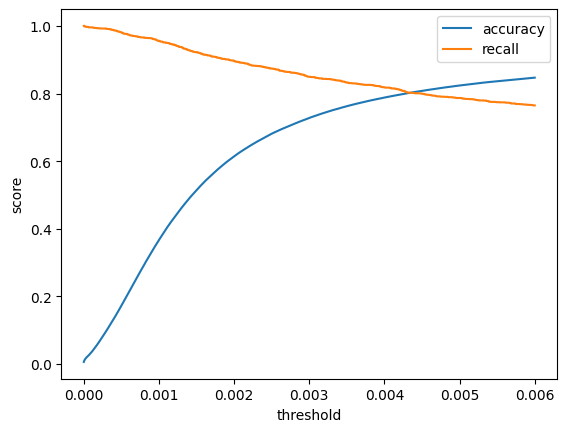

In [179]:
plt.plot(thrs,accs, label = 'accuracy')
plt.plot(thrs, recs, label = 'recall')
plt.legend()
plt.xlabel('threshold')
plt.ylabel('score')
plt.show()

In [180]:
#  It should not come as a surprise based on our previous values that our threshold needs to be very low to have any amount of recall. 
# Recall is more important to us than accuracy, but we cannot throw away all our accuracy
# 
acc_pct = 10000 * np.array(accs)
rec_pct = 10000 * np.array(recs)
thresh = thrs[rec_pct.astype(int) == acc_pct.astype(int)]
print('best threshold(s):',thresh)
# We have a few values with tied recall and accuracy when rounded to 4 decimal places (ten-thousandths). We will take the lowestr value for our final model because if there is a small difference it'll have the highest recall

best threshold(s): [0.00434  0.004341 0.004342]


In [181]:
bestmodel = LogisticRegression(penalty='l2', C = best_c)
bestmodel.fit(X_train_poly_scaled,y_train)
y_test_probs = poly_model.predict_proba(X_test_poly_scaled)[:,1]
y_train_probs = poly_model.predict_proba(X_train_poly_scaled)[:,1]
y_test_pred = y_test_probs > thresh[0]
y_train_pred = y_train_probs > thresh[0]
train_acc, train_rec, train_roc_auc = accuracy_score(y_train,y_train_pred), recall_score(y_train,y_train_pred), roc_auc_score(y_train,y_train_probs)
test_acc, test_rec, test_roc_auc = accuracy_score(y_test,y_test_pred), recall_score(y_test,y_test_pred), roc_auc_score(y_test,y_test_probs)
scores['Best Model'] = {'train acc':train_acc, 'train rec':train_rec, 'train roc auc':train_roc_auc, 'test acc':test_acc,'test rec':test_rec,'test roc auc':test_roc_auc}
scores['Best Model']

{'train acc': 0.8017890368701953,
 'train rec': 0.8400383141762452,
 'train roc auc': 0.8954687826729012,
 'test acc': 0.8034691279439847,
 'test rec': 0.8313492063492064,
 'test roc auc': 0.8864683849595412}

## 6) Inference

In [182]:
# For smf we merge predictors and response
train = pd.merge(X_train.reset_index(),pd.DataFrame(y_train).reset_index())
test = pd.merge(X_test.reset_index(),pd.DataFrame(y_test).reset_index())


In [183]:
# Quirk of smf, we need to change boolean to int
train['Fatal'] = train['Fatal'].astype(int)

In [184]:
# Luckily for us, since the datset is so large, we will almost always have very small standard errors, meaning we can be very confident in the significance/lack thereof in our data

In [185]:
smf_model = smf.logit(data = train, formula='Fatal~Victim_Age+I(Victim_Age**2)+Minutes+I(Minutes**2)+Day+I(Day**2)+Month+I(Month**2)+Year+I(Year**2)+Victim_Sex+Hit+Area_Name').fit()
smf_model.summary()

         Current function value: 0.029623
         Iterations: 35


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                  Fatal   No. Observations:               326768
Model:                          Logit   Df Residuals:                   326730
Method:                           MLE   Df Model:                           37
Date:                Mon, 16 Mar 2026   Pseudo R-squ.:                  0.2337
Time:                        12:54:32   Log-Likelihood:                -9679.8
converged:                      False   LL-Null:                       -12632.
Covariance Type:            nonrobust   LLR p-value:                     0.000
===================================================================================================
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept                       -1461.6215   7525.517     -0.194      0.846   -1.62e+04    1.33e+04
Victim_Sex[T.M]                     0.2868      0.050      5.682      0.000       0.188       0.386
Hit[T.Object]                      -0.7787      0.119     -6.528      0.000      -1.012      -0.545
Hit[T.Parked Vehicle]              -2.8396      0.152    -18.638      0.000      -3.138      -2.541
Hit[T.Pedestrian]                   1.3279      0.090     14.780      0.000       1.152       1.504
Hit[T.Train]                       -0.8655      1.012     -0.855      0.393      -2.850       1.119
Hit[T.Vehicle]                     -1.6654      0.098    -17.053      0.000      -1.857      -1.474
Hit[T.Vehicle On Other Roadway]    -1.7493      1.006     -1.738      0.082      -3.722       0.223
Area_Name[T.Central]               -0.9501      0.145     -6.572      0.000      -1.233      -0.667
Area_Name[T.Devonshire]             0.2667      0.121      2.212      0.027       0.030       0.503
Area_Name[T.Foothill]               0.3614      0.120      3.006      0.003       0.126       0.597
Area_Name[T.Harbor]                 0.1621      0.125      1.296      0.195      -0.083       0.407
Area_Name[T.Hollenbeck]            -0.2148      0.137     -1.564      0.118      -0.484       0.054
Area_Name[T.Hollywood]             -1.0548      0.160     -6.576      0.000      -1.369      -0.740
Area_Name[T.Mission]                0.1225      0.121      1.013      0.311      -0.114       0.359
Area_Name[T.N Hollywood]           -0.3149      0.132     -2.387      0.017      -0.574      -0.056
Area_Name[T.Newton]                -0.2488      0.118     -2.117      0.034      -0.479      -0.018
Area_Name[T.Northeast]             -0.3932      0.140     -2.818      0.005      -0.667      -0.120
Area_Name[T.Olympic]               -0.7359      0.135     -5.438      0.000      -1.001      -0.471
Area_Name[T.Pacific]               -0.5319      0.135     -3.942      0.000      -0.796      -0.267
Area_Name[T.Rampart]               -0.4983      0.138     -3.599      0.000      -0.770      -0.227
Area_Name[T.Southeast]              0.2709      0.111      2.436      0.015       0.053       0.489
Area_Name[T.Southwest]             -0.1730      0.116     -1.487      0.137      -0.401       0.055
Area_Name[T.Topanga]               -0.1330      0.134     -0.990      0.322      -0.396       0.130
Area_Name[T.Van Nuys]              -0.5276      0.144     -3.661      0.000      -0.810      -0.245
Area_Name[T.West LA]               -0.4199      0.141     -2.985      0.003      -0.696      -0.144
Area_Name[T.West Valley]           -0.0634      0.125     -0.507      0.612      -0.309       0.182
Area_Name[T.Wilshire]              -0.5264      0.140     -3.767      0.000      -0.800      -0.253
Victim_Age                          0.0320      0.006      5.767      0.000       0.021       0.043
I(Victim_Age ** 2)                 -0.000